# Assignment 4 — CIFAR-10 ConvNet

**DATAX504** · Due end of Week 8

Build on **Chapter 8** (ConvNets, augmentation) and ideas from **Chapters 9–10** (interpretation). You design the stack; the goal is a working pipeline you can explain, not a copy of a tutorial.

## Tasks
1. Load CIFAR-10, normalise, create a train / validation split
2. Build a **data augmentation** pipeline used during training
3. Train a **ConvNet** that reaches **>65%** test accuracy
4. Visualise at least one filter / feature (layer weights or activation-based)
5. Brief interpretation of what that filter responds to (Moodle `a4_interpretation`)

## Moodle fields
`a4_repo`, `a4_test_acc`, `a4_filter_layer`, `a4_interpretation`

## AI disclosure (required)
Fill the table in the next cell before you submit.


## AI disclosure

| Field | Your answer |
|-------|-------------|
| Tool / model |ChatGPT + GPT-6 Astra |
| Used for | |
| Verified how | |
| Not used for | |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers


## 1. Load & prepare CIFAR-10

Hints:
- `keras.datasets.cifar10.load_data()`
- cast pixels to float and scale to `[0, 1]` (or another range you document)
- flatten label shape if needed (`y.ravel()`)
- hold out a validation slice from the training set (e.g. last 5_000 or 10_000)


In [2]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# TODO: preprocess x_* and reshape / ravel y_* as needed
# Convert pixels to float32 and scale them from [0, 255] to [0, 1].
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
# Convert labels from shape (N, 1) to (N,).
y_train = y_train.ravel()
y_test = y_test.ravel()

# TODO: validation split from training data
# Reserve the last 5,000 training examples for validation.
x_val = x_train[-5000:]
y_val = y_train[-5000:]

x_train = x_train[:-5000]
y_train = y_train[:-5000]

print("train:", getattr(x_train, "shape", None), getattr(y_train, "shape", None))
print("val:  ", getattr(x_val, "shape", None), getattr(y_val, "shape", None))
print("test: ", getattr(x_test, "shape", None), getattr(y_test, "shape", None))


train: (45000, 32, 32, 3) (45000,)
val:   (5000, 32, 32, 3) (5000,)
test:  (10000, 32, 32, 3) (10000,)


## 2. Data augmentation

Build a small `keras.Sequential` of image layers (e.g. flip / rotation / zoom).
Apply it **inside** the model (or as a preprocessing layer) so training sees augmented batches.

Preview a few transforms on one training image to check it works.


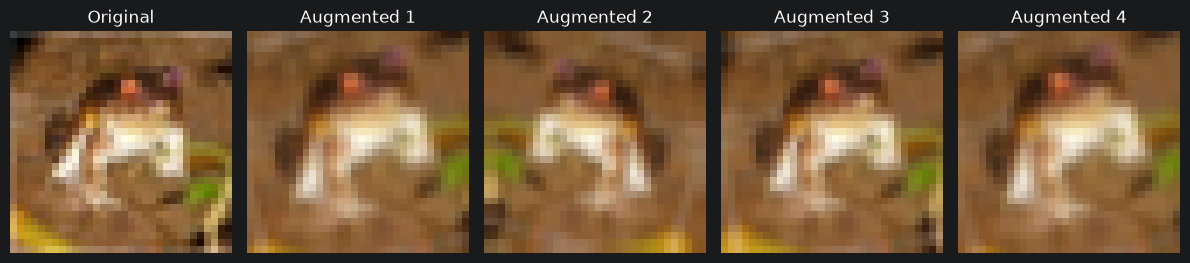

In [4]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05, fill_mode="reflect"),
        layers.RandomZoom(0.1, fill_mode="reflect"),
    ],
    name="augmentation",
)

# Select one training image, keeping the batch dimension
sample = x_train[:1]

# TODO: preview — take one image from x_train, run it through data_augmentation a few times, plot
# Display the original image and four augmented versions
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

axes[0].imshow(sample[0])
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(1, 5):
    # Enable augmentation explicitly for this preview.
    augmented = data_augmentation(sample, training=True)
    augmented_image = keras.ops.convert_to_numpy(augmented[0])

    axes[i].imshow(np.clip(augmented_image, 0.0, 1.0))
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


## 3. ConvNet model

Requirements:
- Input shape `(32, 32, 3)`
- Include your augmentation as the first stage of the graph (training only behaviour is fine)
- At least two `Conv2D` + pooling stages, then a dense classifier for 10 classes
- Name at least one early conv layer (you will need the name for visualisation)

Compile with a suitable loss for integer class labels (or one-hot — be consistent).


In [5]:
inputs = keras.Input(shape=(32, 32, 3))

# Apply augmentation during training.
x = data_augmentation(inputs)


# TODO: Conv / pool / (optional BatchNorm, Dropout) stack
# Block 1: learn simple local features.
x = layers.Conv2D(
    32, (3, 3),
    padding="same",
    activation="relu",
    name="conv2d_1",
)(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Block 2: combine features into more complex patterns.
x = layers.Conv2D(
    64, (3, 3),
    padding="same",
    activation="relu",
    name="conv2d_2",
)(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Block 3: learn higher-level feature combinations.
x = layers.Conv2D(
    128, (3, 3),
    padding="same",
    activation="relu",
    name="conv2d_3",
)(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Convert feature maps into a vector for classification.
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)

# TODO: classifier head → 10-class output
# Predict probabilities for the 10 classes.
outputs = layers.Dense(10, activation="softmax")(x)
# Build and compile the model for integer class labels.
model = keras.Model(inputs, outputs, name="cifar10_convnet")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()
print("Model ready:", model is not None)


Model: "cifar10_convnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Model ready: True


## 4. Train & evaluate

Fit with `validation_data`. Aim for **>65%** test accuracy (Moodle wants the percentage).
Plot train vs val accuracy if useful for your write-up.


Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.3684 - loss: 1.7161 - val_accuracy: 0.4876 - val_loss: 1.4548
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.4865 - loss: 1.4205 - val_accuracy: 0.5654 - val_loss: 1.1976
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5515 - loss: 1.2678 - val_accuracy: 0.6078 - val_loss: 1.0976
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5893 - loss: 1.1707 - val_accuracy: 0.6610 - val_loss: 0.9581
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6095 - loss: 1.1133 - val_accuracy: 0.6948 - val_loss: 0.8729
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6293 - loss: 1.0591 - val_accuracy: 0.7058 - val_loss: 0.8365
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6473 - loss: 1.0102 - val_accuracy: 0.7024 - val_loss: 0.8534
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6604 - loss: 0.9827 - val_accu

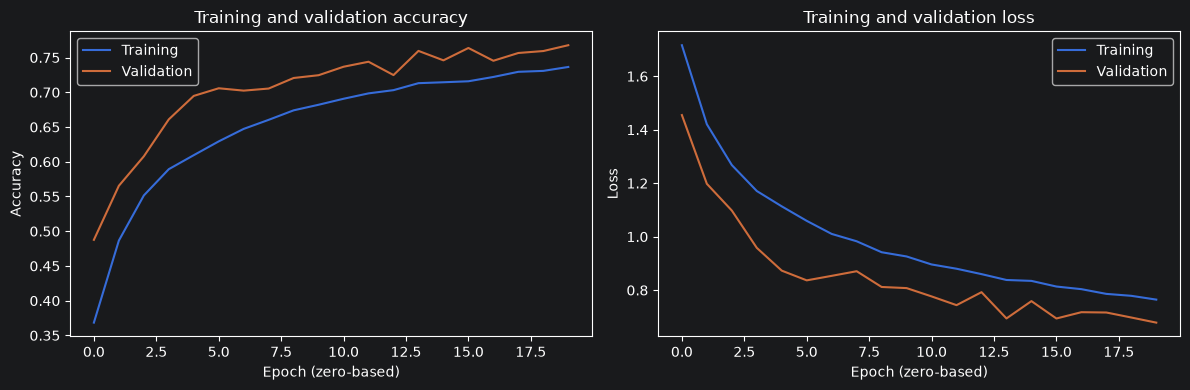

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7580 - loss: 0.7074 
Test loss: 0.7074
Test accuracy % (Moodle a4_test_acc): 75.80
Meets >65% requirement: True
Test accuracy % (Moodle a4_test_acc): 75.80000162124634


In [6]:
# TODO: fit
# Train the model using the separate validation set.
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(x_val, y_val),
    # callbacks=[reduce_lr],
    shuffle=True,
    verbose=1,
)

# Plot training and validation accuracy and loss.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Training and validation accuracy")
axes[0].set_xlabel("Epoch (zero-based)")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Training and validation loss")
axes[1].set_xlabel("Epoch (zero-based)")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

# Evaluate the selected model once on the test set.
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    batch_size=64,
    verbose=1,
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy % (Moodle a4_test_acc): {100 * test_acc:.2f}")
print("Meets >65% requirement:", test_acc > 0.65)

# TODO: evaluate once on the test set
print(f"Test accuracy % (Moodle a4_test_acc): {100 * test_acc if test_acc is not None else None}")
model.save("a4_convnet.keras")


## 5. Filter visualisation

Pick a named conv layer (`a4_filter_layer`). Minimum expectation: plot first-layer filter weights as small images.

Optional deeper approach: gradient ascent / activation maximisation for one filter index (Ch 10 style).


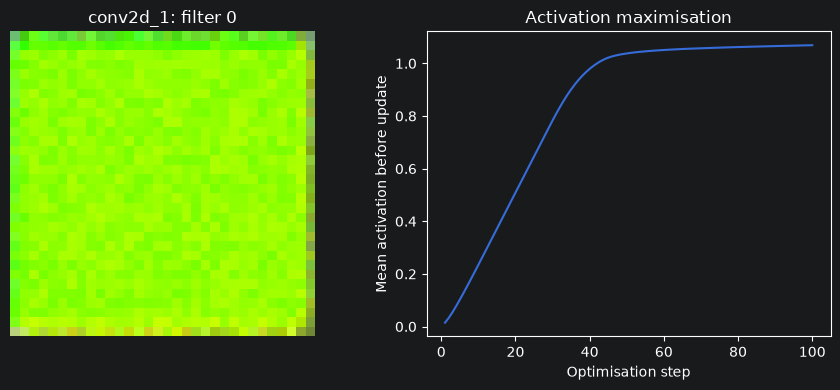

Visualisation layer (Moodle a4_filter_layer): conv2d_1


In [7]:
import tensorflow as tf

VIS_LAYER = "conv2d_1"
FILTER_INDEX = 0

# TODO: get the layer, extract weights, plot a grid of filters
# Get the layer
conv_layer = model.get_layer(VIS_LAYER)
# Use layer activations instead of extracting filter weights
feature_model = keras.Model(
    inputs=model.inputs,
    outputs=conv_layer.output,
)
# Create a random starting image.
image = tf.Variable(
    tf.random.stateless_uniform(
        shape=(1, 32, 32, 3),
        seed=(504, 0),
        minval=0.4,
        maxval=0.6,
    )
)
steps = 100
step_size = 0.01
scores = []
# Generate a pattern that maximises the selected filter's activation.
for step in range(steps):
    with tf.GradientTape() as tape:
        # Disable random augmentation during visualisation.
        activations = feature_model(image, training=False)

        # Exclude border positions affected by padding.
        score = tf.reduce_mean(
            activations[:, 1:-1, 1:-1, FILTER_INDEX]
        )

    gradients = tape.gradient(score, image)
    # Normalise gradients to control the update size.
    gradients = gradients / (
        tf.sqrt(tf.reduce_mean(tf.square(gradients))) + 1e-8
    )
    # Update the input image, not the model weights.
    image.assign_add(step_size * gradients)
    image.assign(tf.clip_by_value(image, 0.0, 1.0))
    scores.append(float(score.numpy()))

# Plot an activation-maximizing pattern instead of a weight grid.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image.numpy()[0], interpolation="nearest")
axes[0].set_title(f"{VIS_LAYER}: filter {FILTER_INDEX}")
axes[0].axis("off")

axes[1].plot(range(1, steps + 1), scores)
axes[1].set_title("Activation maximisation")
axes[1].set_xlabel("Optimisation step")
axes[1].set_ylabel("Mean activation before update")

plt.tight_layout()
plt.show()

print(f"Visualisation layer (Moodle a4_filter_layer): {VIS_LAYER}")

## 6. Interpretation (Moodle `a4_interpretation`)

Max ~200 words: what pattern does your chosen filter respond to?


I visualised filter 0 in the first convolutional layer, conv2d_1, using activation maximisation. Starting from a random image, I adjusted the input pixels while keeping the model weights fixed and disabling data augmentation.
During each optimisation step, gradients indicated how the input pixels should change to increase the selected response. Pixel values were kept within the normalised range of zero to one. The smooth rise in the activation curve, followed by a plateau, makes the optimisation process easy to observe. Together, the image and curve illustrate the relationship between the input pattern and activation.
The generated image is predominantly bright yellow-green, suggesting that this filter responds to yellow-green colour features. Its mean activation increased from near zero to approximately 1.07 and then stabilised, showing that the optimisation successfully found a pattern that strongly activates the filter. This provides an example of how an early convolutional layer can learn simple colour features that later layers can combine into more complex representations.